# Assignment 6 - Tic-Tac-Toe using Reinforcement Learning

Build and train a Q-learning agent to play Tic-Tac-Toe.

## 1. Setting up the environment

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

## 2. Defining the Tic-Tac-Toe game

In [2]:
class TicTacToe:
    def __init__(self):
        self.winning_lines = (
            (0, 1, 2), (3, 4, 5), (6, 7, 8),
            (0, 3, 6), (1, 4, 7), (2, 5, 8),
            (0, 4, 8), (2, 4, 6),
        )
        self.reset()

    def reset(self):
        self.board = [0] * 9
        return tuple(self.board)

    def available_actions(self):
        return [i for i, value in enumerate(self.board) if value == 0]

    def winner(self):
        for a, b, c in self.winning_lines:
            if (
                self.board[a] != 0
                and self.board[a] == self.board[b] == self.board[c]
            ):
                return self.board[a]
        return 0

    def step(self, action, player):
        if action not in self.available_actions():
            raise ValueError("Action must be an available board position")
        self.board[action] = player
        winner = self.winner()
        done = winner != 0 or not self.available_actions()
        return tuple(self.board), winner, done

    def display(self):
        symbols = {0: " ", 1: "X", -1: "O"}
        for row in range(0, 9, 3):
            print(" | ".join(symbols[x] for x in self.board[row:row + 3]))
            if row < 6:
                print("---------")

## 3. Building the reinforcement learning model

In [3]:
class QLearningAgent:
    def __init__(self, learning_rate=0.2, discount=0.95, epsilon=1.0):
        self.q_table = {}
        self.learning_rate = learning_rate
        self.discount = discount
        self.epsilon = epsilon

    def values(self, state):
        if state not in self.q_table:
            self.q_table[state] = np.zeros(9)
        return self.q_table[state]

    def choose_action(self, state, actions, explore=True):
        if explore and random.random() < self.epsilon:
            return random.choice(actions)
        values = self.values(state).copy()
        values[[i for i in range(9) if i not in actions]] = -np.inf
        return int(np.argmax(values))

    def update(self, state, action, reward, next_state, next_actions, done):
        current = self.values(state)[action]
        future = 0 if done else np.max(self.values(next_state)[next_actions])
        target = reward + self.discount * future
        self.q_table[state][action] += self.learning_rate * (target - current)

## 4. Training the model

In [4]:
def train_agent(episodes=20000):
    agent = QLearningAgent()
    results = []

    for episode in range(episodes):
        game = TicTacToe()
        state = game.reset()
        previous_state = None
        previous_action = None

        while True:
            actions = game.available_actions()
            action = agent.choose_action(state, actions)
            next_state, winner, done = game.step(action, 1)

            if done:
                reward = 1 if winner == 1 else 0
                agent.update(state, action, reward, next_state, [], True)
                results.append(winner)
                break

            opponent_action = random.choice(game.available_actions())
            next_state, winner, done = game.step(opponent_action, -1)
            reward = -1 if winner == -1 else (0 if done else 0)
            agent.update(
                state, action, reward, next_state,
                game.available_actions(), done
            )

            if done:
                results.append(winner)
                break
            state = next_state

        agent.epsilon = max(0.05, agent.epsilon * 0.9997)

    return agent, results

agent, training_results = train_agent()
print("Learned states:", len(agent.q_table))
print("Final exploration rate:", round(agent.epsilon, 3))

Learned states: 2161
Final exploration rate: 0.05


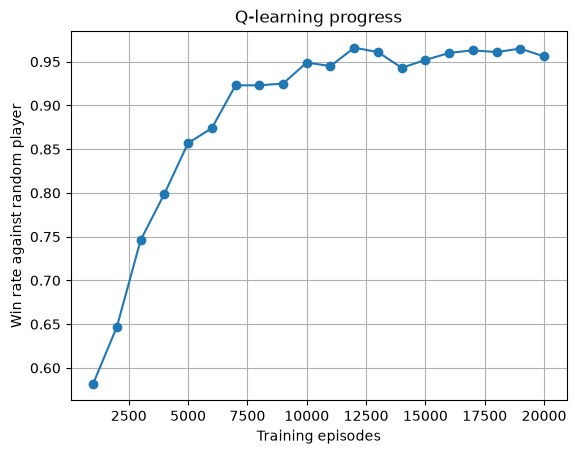

In [5]:
window = 1000
win_rates = [
    np.mean(np.array(training_results[i:i + window]) == 1)
    for i in range(0, len(training_results), window)
]

plt.plot(range(window, len(training_results) + 1, window), win_rates, marker="o")
plt.xlabel("Training episodes")
plt.ylabel("Win rate against random player")
plt.title("Q-learning progress")
plt.grid(True)
plt.show()

## 5. Testing the model

In [6]:
def test_agent(agent, games=1000):
    outcomes = {1: 0, -1: 0, 0: 0}
    for _ in range(games):
        game = TicTacToe()
        state = game.reset()
        while True:
            action = agent.choose_action(
                state, game.available_actions(), explore=False
            )
            state, winner, done = game.step(action, 1)
            if done:
                outcomes[winner] += 1
                break
            action = random.choice(game.available_actions())
            state, winner, done = game.step(action, -1)
            if done:
                outcomes[winner] += 1
                break
    return outcomes

test_results = test_agent(agent)
print("Test results:", test_results)
print("Test win rate:", round(test_results[1] / 1000 * 100, 2), "%")

Test results: {1: 983, -1: 0, 0: 17}
Test win rate: 98.3 %


In [7]:
game = TicTacToe()
state = game.reset()

while True:
    action = agent.choose_action(state, game.available_actions(), explore=False)
    state, winner, done = game.step(action, 1)
    if done:
        break
    opponent_action = random.choice(game.available_actions())
    state, winner, done = game.step(opponent_action, -1)
    if done:
        break

game.display()
result = (
    "Agent wins" if winner == 1
    else "Random player wins" if winner == -1
    else "Draw"
)
print("Result:", result)

X | X | X
---------
O |   |  
---------
O |   |  
Result: Agent wins


## Conclusion

The Q-learning agent learns action values from rewards and improves its Tic-Tac-Toe performance through repeated games against a random opponent.